In [5]:
from pytom_tm.tmjob import TMJob
from pytom_tm.parallel import run_job_parallel
from pathlib import Path
import numpy as np
import mrcfile
from skimage.feature import peak_local_max
from matplotlib import pyplot as plt
import torch.nn.functional as F
import torch
import einops
from torch_subpixel_crop.dft_utils import dft_center

In [2]:
tomograms = [
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_7/patch_tracking/20240621_15F1Fab-AuNP_7_full_rec_BP_flat.mrc"),
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_8/patch_tracking/20240621_15F1Fab-AuNP_8_full_rec_BP_flat.mrc"),
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_9/patch_tracking/20240621_15F1Fab-AuNP_9_full_rec_BP_flat.mrc")
]
template = Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/temaplte.mrc")
mask = Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/mask.mrc")
angles = Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/angles.txt")

In [19]:
def calc_3dtm(tomo):
    job = TMJob(
        "0",
        20,
        tomo,
        template,
        mask,
        Path('./'),
        angle_increment=str(angles),
        mask_is_spherical=True,
        tilt_angles=[-48,48],
        tilt_weighting=None,
        search_x=None,
        search_y=None,
        search_z=[50,350],
        tomogram_mask=None,
        voxel_size=10.0,
        low_pass=None,
        high_pass=None,
        dose_accumulation=None,
        ctf_data=None,
        whiten_spectrum=True,
        rotational_symmetry=1,
        particle_diameter=None,
        random_phase_correction=False,
        rng_seed=5,
    )

    score_volume, angle_volume = run_job_parallel(
        job, (2,2,2), [0]
    )
   
    peaks = peak_local_max(score_volume, min_distance=10, threshold_abs=0.5, exclude_border=True)
    locations_tomo = torch.Tensor(peaks[:,::-1].copy()+ np.array([50,0,0])) # FRom XYZ to ZYX
    return locations_tomo, torch.Tensor(peaks).int(), score_volume

In [20]:
locations, locations_score, score_volume = calc_3dtm(tomograms[0])

Progress job_00 on device 0:


100%|████████████████████████████████████████████| 1/1 [00:00<00:00,  9.10it/s]


Progress job_01 on device 0:


100%|███████████████████████████████████████████| 1/1 [00:00<00:00, 708.26it/s]


Progress job_02 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1403.25it/s]


... (6 outputs left out)

Progress job_06 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1525.76it/s]


Progress job_07 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1559.80it/s]


In [17]:
score_volume = torch.tensor(score_volume)
score_volume.shape

/tmp/ipykernel_106435/3062737954.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  score_volume = torch.tensor(score_volume)


torch.Size([856, 1204, 300])

In [24]:

# Get value of score at each location
scores = score_volume[locations_score[:,0], locations_score[:,1], locations_score[:,2]]
scores

array([0.78201777, 0.7777969 , 0.7742538 , ..., 0.50181824, 0.5003355 ,
       0.50027406], dtype=float32)

In [79]:
import torch
import torch.nn as nn
import torch.optim as optim
from concurrent.futures import ThreadPoolExecutor

class Gaussian3D(nn.Module):
    def __init__(self):
        super(Gaussian3D, self).__init__()
        self.amplitude = nn.Parameter(torch.tensor(1.0))
        self.x0 = nn.Parameter(torch.tensor(0.0))
        self.y0 = nn.Parameter(torch.tensor(0.0))
        self.z0 = nn.Parameter(torch.tensor(0.0))
        self.sigma_x = nn.Parameter(torch.tensor(1.0))
        self.sigma_y = nn.Parameter(torch.tensor(1.0))
        self.sigma_z = nn.Parameter(torch.tensor(1.0))

    def forward(self, x, y, z):
        return self.amplitude * torch.exp(
            -((x - self.x0) ** 2 / (2 * self.sigma_x ** 2) +
              (y - self.y0) ** 2 / (2 * self.sigma_y ** 2) +
              (z - self.z0) ** 2 / (2 * self.sigma_z ** 2))
        )

def fit_single_gaussian(score_volume, loc, boxsize=10, iterations=500, lr=0.01):
    x, y, z = loc
    # Extract a small region around the location for fitting with boxsize sidelength
    region = score_volume[x-boxsize//2:x+boxsize//2+1, y-boxsize//2:y+boxsize//2+1, z-boxsize//2:z+boxsize//2+1]
    coords = torch.stack(torch.meshgrid(
        torch.arange(region.shape[0]),
        torch.arange(region.shape[1]),
        torch.arange(region.shape[2])
    ), dim=-1).reshape(-1, 3) - torch.tensor([boxsize//2, boxsize//2, boxsize//2])

    x_coords = coords[:, 0].float().to(score_volume.device)
    y_coords = coords[:, 1].float().to(score_volume.device)
    z_coords = coords[:, 2].float().to(score_volume.device)
    region = region.reshape(-1).float().to(score_volume.device)

    model = Gaussian3D().to(score_volume.device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    for _ in range(iterations):  # Reduced number of iterations
        optimizer.zero_grad()
        output = model(x_coords, y_coords, z_coords)
        loss = criterion(output, region)
        loss.backward()
        optimizer.step()

    return {
        'amplitude': model.amplitude.item(),
        'x0': model.x0.item(),
        'y0': model.y0.item(),
        'z0': model.z0.item(),
        'sigma_x': model.sigma_x.item(),
        'sigma_y': model.sigma_y.item(),
        'sigma_z': model.sigma_z.item(),
        'loss' : loss.item()
    }

def fit_gaussian_3d(score_volume, locations, boxsize=10, iterations=500, lr=0.01):
    fitted_params = []

    with ThreadPoolExecutor() as executor:
        futures = [executor.submit(fit_single_gaussian, score_volume, loc, boxsize, iterations, lr) for loc in locations]
        for future in futures:
            fitted_params.append(future.result())

    return fitted_params

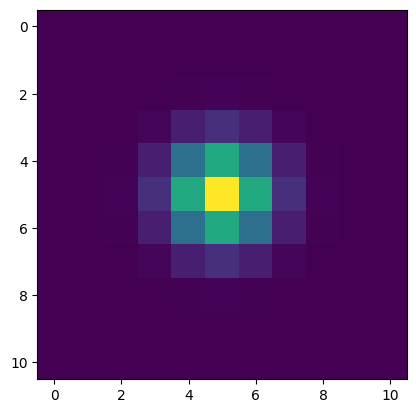

In [51]:
model = Gaussian3D()
coords = torch.stack(torch.meshgrid(
            torch.arange(11),
            torch.arange(11),
            torch.arange(11)
        ), dim=-1).reshape(-1, 3) - torch.tensor([5,5,5])

x_coords = coords[:, 0].float()
y_coords = coords[:, 1].float()
z_coords = coords[:, 2].float()
md = model(x_coords, y_coords, z_coords).detach().numpy().reshape(11,11,11)
plt.imshow(md[5])

In [94]:
#score_volume_gpu = torch.tensor(score_volume).cuda()
#locations_score_gpu = locations_score.cuda()
fitted_params = fit_gaussian_3d(torch.tensor(score_volume_gpu), locations_score_gpu,6,iterations=500,lr=0.05)
fitted_params

/tmp/ipykernel_106435/4056795306.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  fitted_params = fit_gaussian_3d(torch.tensor(score_volume_gpu), locations_score_gpu,6,iterations=500,lr=0.05)


[{'amplitude': 0.7943793535232544,
  'x0': 0.05844961106777191,
  'y0': 0.1492752879858017,
  'z0': -0.030893851071596146,
  'sigma_x': 0.7899577021598816,
  'sigma_y': 0.9248886108398438,
  'sigma_z': 2.6069140434265137,
  'loss': 0.01004483550786972},
 {'amplitude': 0.7805243730545044,
  'x0': 0.06942851096391678,
  'y0': 0.045374795794487,
  'z0': 0.01480843871831894,
  'sigma_x': 0.7787594199180603,
  'sigma_y': 0.9253737330436707,
  'sigma_z': 2.6069605350494385,
  'loss': 0.010054840706288815},
 {'amplitude': 0.7484870553016663,
  'x0': 0.04969211667776108,
  'y0': 0.0672256350517273,
  'z0': 0.11250621825456619,
  'sigma_x': 0.782558023929596,
  'sigma_y': 1.016470193862915,
  'sigma_z': 2.724355459213257,
  'loss': 0.007871258072555065},
 {'amplitude': 0.8181887865066528,
  'x0': 0.21681158244609833,
  'y0': -0.21850532293319702,
  'z0': 0.09610003232955933,
  'sigma_x': 0.7870475053787231,
  'sigma_y': 0.9055566787719727,
  'sigma_z': 2.9358749389648438,
  'loss': 0.0094896843

In [95]:
sum([fp['loss'] for fp in fitted_params])

18.683236031793058

# It 100 lr 0.1 sum loss 18.68
# It 500 lr 0.1 sum loss 18.68
# It 50 lr 0.1 sum loss 18.71
# It 50 lr 0.2 sum loss 18.75
# It 50 lr 0.05 sum loss 18.80
# It 100 lr 0.05 sum loss 18.70
# It 100 lr 0.1 sum loss 18.68
# It 500 lr 0.05 sum loss 18.68

In [78]:
fitted_params[-1]

{'amplitude': 0.5832066535949707,
 'x0': 0.20096959173679352,
 'y0': 0.09877520054578781,
 'z0': -0.468938946723938,
 'sigma_x': 0.8382115960121155,
 'sigma_y': 1.0209159851074219,
 'sigma_z': 2.3926267623901367}

In [112]:
class Gaussian3DList(nn.Module):
    def __init__(self, num_gaussians):
        super(Gaussian3DList, self).__init__()
        self.amplitude = nn.Parameter(torch.ones(num_gaussians))
        self.x0 = nn.Parameter(torch.zeros(num_gaussians))
        self.y0 = nn.Parameter(torch.zeros(num_gaussians))
        self.z0 = nn.Parameter(torch.zeros(num_gaussians))
        self.sigma_x = nn.Parameter(torch.ones(num_gaussians))
        self.sigma_y = nn.Parameter(torch.ones(num_gaussians))
        self.sigma_z = nn.Parameter(torch.ones(num_gaussians))

    def forward(self, x, y, z):
        
        x = x.unsqueeze(0)  # Shape: (num_points, num_gaussians)
        y = y.unsqueeze(0)
        z = z.unsqueeze(0)
        return self.amplitude.unsqueeze(1) * torch.exp(
            -((x - self.x0.unsqueeze(1)) ** 2 / (2 * self.sigma_x.unsqueeze(1) ** 2) +
              (y - self.y0.unsqueeze(1)) ** 2 / (2 * self.sigma_y.unsqueeze(1) ** 2) +
              (z - self.z0.unsqueeze(1)) ** 2 / (2 * self.sigma_z.unsqueeze(1) ** 2))
        )  # Sum over the gaussians

def fit_gaussian_3d_list(score_volume, locations, boxsize):
    num_gaussians = len(locations)
    model = Gaussian3DList(num_gaussians).to(score_volume.device)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    # Prepare the 4D tensor of boxes
    boxes = []
    for loc in locations:
        x, y, z = loc
        region = score_volume[x-boxsize//2:x+boxsize//2+1, y-boxsize//2:y+boxsize//2+1, z-boxsize//2:z+boxsize//2+1]
        boxes.append(region)
    boxes = torch.stack(boxes).to(score_volume.device)  # Shape: (num_gaussians, boxsize, boxsize, boxsize)

    # Prepare the coordinates
    coords = torch.stack(torch.meshgrid(
        torch.arange(boxsize+1),
        torch.arange(boxsize+1),
        torch.arange(boxsize+1)
    ), dim=-1).reshape(-1, 3).to(score_volume.device) - torch.tensor([boxsize//2, boxsize//2, boxsize//2], device=score_volume.device)
    x_coords = coords[:, 0].float()
    y_coords = coords[:, 1].float()
    z_coords = coords[:, 2].float()

    for _ in range(1000):  # Number of iterations
        optimizer.zero_grad()
        output = model(x_coords, y_coords, z_coords).reshape(num_gaussians, boxsize+1, boxsize+1, boxsize+1)
        loss = criterion(output, boxes)
        loss.backward()
        optimizer.step()

    fitted_params = []
    for i in range(num_gaussians):
        fitted_params.append({
            'amplitude': model.amplitude[i].item(),
            'x0': model.x0[i].item(),
            'y0': model.y0[i].item(),
            'z0': model.z0[i].item(),
            'sigma_x': model.sigma_x[i].item(),
            'sigma_y': model.sigma_y[i].item(),
            'sigma_z': model.sigma_z[i].item(),
            'loss': loss.item()
        })

    return fitted_params

In [113]:
#score_volume_gpu = torch.tensor(score_volume).cuda()
#locations_score_gpu = locations_score.cuda()
fitted_params_list = fit_gaussian_3d_list(torch.tensor(score_volume_gpu), locations_score_gpu,6)
fitted_params_list

/tmp/ipykernel_106435/1345081727.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  fitted_params_list = fit_gaussian_3d_list(torch.tensor(score_volume_gpu), locations_score_gpu,6)


[{'amplitude': 0.7952068448066711,
  'x0': 0.05847029760479927,
  'y0': 0.14924675226211548,
  'z0': -0.030766561627388,
  'sigma_x': 0.7899115085601807,
  'sigma_y': 0.9248875975608826,
  'sigma_z': 2.5997955799102783,
  'loss': 0.008760406635701656},
 {'amplitude': 0.7813352346420288,
  'x0': 0.06945732235908508,
  'y0': 0.045374494045972824,
  'z0': 0.014789974316954613,
  'sigma_x': 0.7786999940872192,
  'sigma_y': 0.9253880381584167,
  'sigma_z': 2.5998663902282715,
  'loss': 0.008760406635701656},
 {'amplitude': 0.7503145933151245,
  'x0': 0.04948772117495537,
  'y0': 0.06718036532402039,
  'z0': 0.11177551746368408,
  'sigma_x': 0.7824182510375977,
  'sigma_y': 1.0164647102355957,
  'sigma_z': 2.7062342166900635,
  'loss': 0.008760406635701656},
 {'amplitude': 0.8237621784210205,
  'x0': 0.21692246198654175,
  'y0': -0.21855852007865906,
  'z0': 0.09408652782440186,
  'sigma_x': 0.7866919040679932,
  'sigma_y': 0.905293345451355,
  'sigma_z': 2.87837553024292,
  'loss': 0.008760

In [117]:
print(fitted_params_list[100])
print(fitted_params[100])

{'amplitude': 0.7442206740379333, 'x0': 0.06956392526626587, 'y0': 0.1252349466085434, 'z0': -0.20286984741687775, 'sigma_x': 0.753154993057251, 'sigma_y': 0.8387654423713684, 'sigma_z': 2.5752487182617188, 'loss': 0.008760406635701656}
{'amplitude': 0.7437058091163635, 'x0': 0.06959495693445206, 'y0': 0.12522998452186584, 'z0': -0.2033010721206665, 'sigma_x': 0.7531812191009521, 'sigma_y': 0.8387617468833923, 'sigma_z': 2.5799331665039062, 'loss': 0.008019590750336647}


In [4]:
subtomos = []
for tomo in tomograms:
    locations, _ = calc_3dtm(tomo)
    with mrcfile.open(tomo, permissive=True) as f:
        tomo_tensor = torch.tensor(f.data)
    subtomos.append(subpixel_crop_3d(tomo_tensor, locations, 20))
subtomos = torch.cat(subtomos, dim=0)
average = einops.reduce(subtomos,'s z y x -> z y x','mean')

Progress job_00 on device 0:


100%|████████████████████████████████████████████| 1/1 [00:00<00:00,  1.25it/s]


Progress job_01 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1519.68it/s]


Progress job_02 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1504.95it/s]


... (7 outputs left out)

100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1426.15it/s]


Progress job_07 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1534.69it/s]


NameError: name 'peak_local_max' is not defined

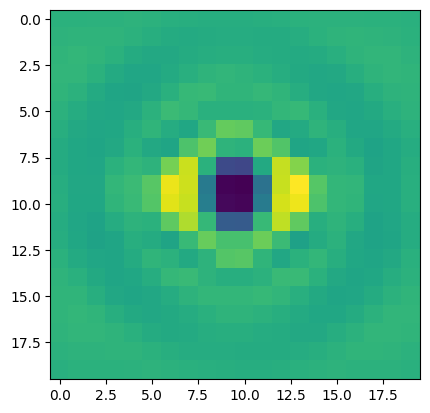

In [89]:
plt.imshow(average[10,:,:])


In [15]:
mrcfile.write("score_volume.mrc", np.transpose(score_volume,(2,1,0)), overwrite=True)

In [67]:
from torch_subpixel_crop import subpixel_crop_3d
import einops

In [44]:
with mrcfile.open(tomograms[0], permissive=True) as f:
    tomogram = torch.tensor(f.data)

In [74]:
peaks = peak_local_max(score_volume, min_distance=10, threshold_abs=0.7, exclude_border=True)
print(peaks.shape)
locations = torch.Tensor(peaks[:,::-1].copy()+ np.array([50,0,0])) # FRom XYZ to ZYX
subtomos = subpixel_crop_3d(tomogram, locations, 20)
subtomos.shape

(372, 3)


torch.Size([372, 20, 20, 20])

tensor([10, 10, 10])

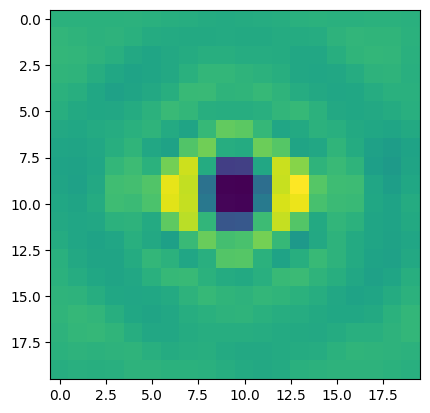

In [78]:
plt.imshow(einops.reduce(subtomos,'s z y x -> z y x','mean').numpy()[10,:,:])
dft_center(subtomos[0].shape,rfft=False, fftshifted=True)

tensor([6, 6, 6])

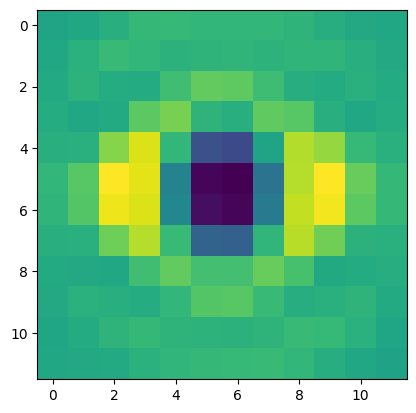

In [82]:
with mrcfile.open(template) as f:
    template_data = f.data.copy()
plt.imshow(template_data[6,:,:])
dft_center(template_data.shape,rfft=False, fftshifted=True)

In [42]:
sv = torch.tensor(score_volume)
for peak in peaks:
    peak_region_z = slice(peak[0] - 2, peak[0] + 3)
    peak_region_y = slice(peak[1] - 2, peak[1] + 3)
    peak_region_x = slice(peak[2] - 2, peak[2] + 3)
    upsampled = F.interpolate(
        einops.rearrange(
            sv[peak_region_z, peak_region_y, peak_region_x],
            'd h w -> 1 1 d h w'
        ),
        scale_factor=10.0,
        mode='trilinear',
        align_corners=True
    )
    upsampled = einops.rearrange(upsampled, '1 1 d h w -> d h w')
    upsampled_center = dft_center(
        upsampled.shape, rfft=False, fftshifted=True,
    )
    print(upsampled_center)
    upsampled_shift = torch.tensor(
        torch.unravel_index(upsampled.argmax().cpu(), shape=upsampled.shape),
    ) - upsampled_center
    print(upsampled_shift/10.0)

tensor([25, 25, 25])
tensor([0., 0., 0.])
tensor([25, 25, 25])
tensor([0., 0., 0.])
tensor([25, 25, 25])
tensor([-0.1000,  0.0000,  0.0000])
tensor([25, 25, 25])
tensor([ 0.0000, -0.1000,  0.0000])
tensor([25, 25, 25])
tensor([ 0.0000, -0.1000, -0.1000])
tensor([25, 25, 25])
tensor([ 0.0000, -0.1000, -0.1000])
tensor([25, 25, 25])
tensor([ 0.0000,  0.0000, -0.1000])
tensor([25, 25, 25])
tensor([0., 0., 0.])
tensor([25, 25, 25])
tensor([ 0.0000,  0.0000, -0.1000])
tensor([25, 25, 25])
tensor([ 0.0000, -0.1000, -0.1000])
tensor([25, 25, 25])
tensor([-0.1000, -0.1000,  0.0000])
tensor([25, 25, 25])
tensor([-0.1000, -0.1000, -0.1000])
tensor([25, 25, 25])
tensor([-0.1000,  0.0000,  0.0000])
tensor([25, 25, 25])
tensor([ 0.0000, -0.1000,  0.0000])
tensor([25, 25, 25])
tensor([0., 0., 0.])
tensor([25, 25, 25])
tensor([-0.1000, -0.1000, -0.1000])
tensor([25, 25, 25])
tensor([-0.1000,  0.0000, -0.1000])
tensor([25, 25, 25])
tensor([-0.1000,  0.0000,  0.0000])
tensor([25, 25, 25])
tensor([-0.10